# Statistical Learning Project

Libraries :

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import shapiro, normaltest, anderson
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.preprocessing import MinMaxScaler, RobustScaler, PolynomialFeatures
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Ridge, Lasso, LassoLarsIC, PoissonRegressor, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
import warnings
from sklearn.exceptions import ConvergenceWarning
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.neural_network import MLPRegressor

Parameters to fix :

In [5]:
select = 3
choice = 1
loo = 1
rd_state = 5
test_size = 0.25

If you want to select the features with variance threshold then set "select" at 1, if you want to select the features with ACP then set "select" at 2 and if you want to select the features with f_regression test then set "select" at 3.

If you want to use MinMaxScaler then set "choice" at 1 anf if you want to use RobustScaler then set "choice" at 2.

If you want to use leave-one-out for LassoCV then set "loo" at 1 and if you want to use 5-folds CV then set "loo" at 2.

For the random state, we study, in particular, the cases rd_state = 47 or 5. 

# First step: Discovering the data set

Installing and importing the Pandas library.

In [12]:
#!pip install pandas
import pandas as pd

Import the ‘.xlsx’ file using the read_excel function.

In [14]:
data = pd.read_excel("Residential-Building-Data-Set.xlsx")

Display the first 5 lines of the dataset.

In [16]:
data.head(5)

,PROJECT DATES (PERSIAN CALENDAR),Unnamed: 1,Unnamed: 2,Unnamed: 3,PROJECT PHYSICAL AND FINANCIAL VARIABLES,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 99,Unnamed: 100,Unnamed: 101,Unnamed: 102,Unnamed: 103,Unnamed: 104,Unnamed: 105,Unnamed: 106,OUTPUTS,Unnamed: 108
0,START YEAR,START QUARTER,COMPLETION YEAR,COMPLETION QUARTER,V-1,V-2,V-3,V-4,V-5,V-6,...,V-22,V-23,V-24,V-25,V-26,V-27,V-28,V-29,V-9,V-10
1,81,1,85,1,1,3150,920,598.5,190,1010.84,...,815.5,1755,8002,60.74,54.26,2978.26,41407,601988.1,2200,410
2,84,1,89,4,1,7600,1140,3040,400,963.81,...,1316.3,8364.78,8393,90.95,89.79,11379.37,44835,929027.1,5000,1000
3,78,1,81,4,1,4800,840,480,100,689.84,...,765.8,1755,4930,38.7,32.04,1653.06,37933,377828.6,1200,170
4,72,2,73,2,1,685,202,13.7,20,459.54,...,152.25,1442.31,1456,9.73,8.34,686.16,8194,122031.7,165,30


Display the last 5 lines of the dataset.

In [18]:
data.tail(5)

,PROJECT DATES (PERSIAN CALENDAR),Unnamed: 1,Unnamed: 2,Unnamed: 3,PROJECT PHYSICAL AND FINANCIAL VARIABLES,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 99,Unnamed: 100,Unnamed: 101,Unnamed: 102,Unnamed: 103,Unnamed: 104,Unnamed: 105,Unnamed: 106,OUTPUTS,Unnamed: 108
368,83,4,86,1,20,1350,350,108,80,251.37,...,1176.5,8343.6,8382,87.27,85.56,10555.47,33626.25,865878.9,1100,150
369,81,2,82,4,20,600,150,36,60,299.55,...,815.5,1755,8013,62.78,56.45,3387.72,10646.75,606524.2,740,80
370,84,4,86,3,20,1900,430,285,150,364.41,...,1584.3,8776.71,8799,101,101.89,13571.8,34474.5,1067772,860,220
371,82,3,84,4,20,510,160,30.6,60,245.28,...,909.2,7930.66,8004,73.57,69.26,4756.68,21855,669640.3,1100,110
372,80,1,81,3,20,890,230,35.6,40,237.03,...,764.5,1755,8420,54.62,44.79,2206.19,40234,629797.2,460,50


We can see that the first line contains the variable names, so we need to add ‘header = 1’ to tell the ‘read_excel’ function to read the file from line 1.

In [20]:
data = pd.read_excel("Residential-Building-Data-Set.xlsx", header = 1)

In [21]:
data.head(5)

,START YEAR,START QUARTER,COMPLETION YEAR,COMPLETION QUARTER,V-1,V-2,V-3,V-4,V-5,V-6,...,V-22.4,V-23.4,V-24.4,V-25.4,V-26.4,V-27.4,V-28.4,V-29.4,V-9,V-10
0,81,1,85,1,1,3150.0,920.0,598.5,190,1010.84,...,815.50,1755.00,8002.0,60.74,54.26,2978.26,41407.0,601988.1,2200,410
1,84,1,89,4,1,7600.0,1140.0,3040.0,400,963.81,...,1316.30,8364.78,8393.0,90.95,89.79,11379.37,44835.0,929027.1,5000,1000
2,78,1,81,4,1,4800.0,840.0,480.0,100,689.84,...,765.80,1755.00,4930.0,38.70,32.04,1653.06,37933.0,377828.6,1200,170
3,72,2,73,2,1,685.0,202.0,13.7,20,459.54,...,152.25,1442.31,1456.0,9.73,8.34,686.16,8194.0,122031.7,165,30
4,87,1,90,2,1,3000.0,800.0,1230.0,410,631.91,...,2244.10,9231.76,9286.0,136.60,140.20,9821.00,48260.0,1734973.5,5500,700


In [22]:
data.tail(5)

,START YEAR,START QUARTER,COMPLETION YEAR,COMPLETION QUARTER,V-1,V-2,V-3,V-4,V-5,V-6,...,V-22.4,V-23.4,V-24.4,V-25.4,V-26.4,V-27.4,V-28.4,V-29.4,V-9,V-10
367,83,4,86,1,20,1350.0,350.0,108.0,80,251.37,...,1176.5,8343.60,8382.0,87.27,85.56,10555.47,33626.25,865878.9,1100,150
368,81,2,82,4,20,600.0,150.0,36.0,60,299.55,...,815.5,1755.00,8013.0,62.78,56.45,3387.72,10646.75,606524.2,740,80
369,84,4,86,3,20,1900.0,430.0,285.0,150,364.41,...,1584.3,8776.71,8799.0,101.00,101.89,13571.80,34474.50,1067772.0,860,220
370,82,3,84,4,20,510.0,160.0,30.6,60,245.28,...,909.2,7930.66,8004.0,73.57,69.26,4756.68,21855.00,669640.3,1100,110
371,80,1,81,3,20,890.0,230.0,35.6,40,237.03,...,764.5,1755.00,8420.0,54.62,44.79,2206.19,40234.00,629797.2,460,50


Display rows with missing values, if any.

In [24]:
if data.isnull().values.any() >=1 :   # Find out if there is at least one missing value 
    data[data.isnull().any(axis=1)]   # Display rows with missing values

So there are no missing values in our dataset.

According to the description of the dataset in Excel, we need to predict the variable ‘V-9’, which corresponds to the selling price. This is our output variable, i.e. our target variable.

Let's take a look at some information on these variables.

In [28]:
print("mean :", data["V-9"].mean())
print("Minimum value :", data["V-9"].min())
print("Maximum value:", data["V-9"].max())
print("median :", data["V-9"].median())

mean : 1387.4327956989248
Minimum value : 50
Maximum value: 6800
median : 1000.0


Let's display a histogram of our target variable.

In [30]:
import matplotlib.pyplot as plt

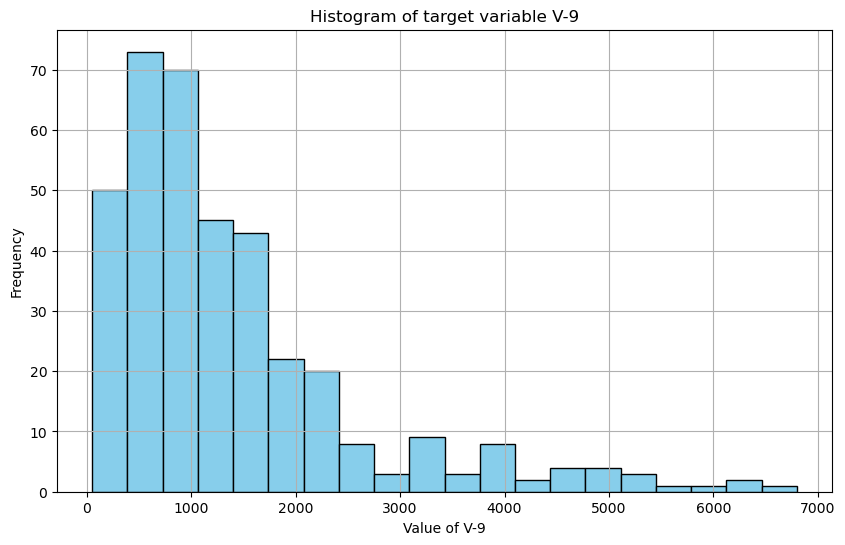

In [31]:
plt.figure(figsize=(10, 6))
plt.hist(data["V-9"].dropna(), bins=20, color="skyblue", edgecolor="black")
plt.title("Histogram of target variable V-9")
plt.xlabel("Value of V-9")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

Normality test for the target variable

In [33]:
from scipy.stats import shapiro, normaltest, anderson

# Cleaning NaN
v9_clean = data["V-9"].dropna()

# Test of Shapiro-Wilk
shapiro_stat, shapiro_p = shapiro(v9_clean)
print("Shapiro-Wilk Test:")
print(f"  Statistic = {shapiro_stat:.4f}, p-value = {shapiro_p:.4f}")

# Test of D'Agostino-Pearson
dagostino_stat, dagostino_p = normaltest(v9_clean)
print("\nD'Agostino-Pearson Test:")
print(f"  Statistic = {dagostino_stat:.4f}, p-value = {dagostino_p:.4f}")

# Test of Anderson-Darling
anderson_result = anderson(v9_clean)
print("\nAnderson-Darling Test:")
print(f"  Statistic = {anderson_result.statistic:.4f}")
for sl, cv in zip(anderson_result.significance_level, anderson_result.critical_values):
    print(f"  Level of signification {sl}% : Critical value = {cv}")

Shapiro-Wilk Test:
  Statistic = 0.8059, p-value = 0.0000

D'Agostino-Pearson Test:
  Statistic = 145.7927, p-value = 0.0000

Anderson-Darling Test:
  Statistic = 21.0049
  Level of signification 15.0% : Critical value = 0.57
  Level of signification 10.0% : Critical value = 0.649
  Level of signification 5.0% : Critical value = 0.779
  Level of signification 2.5% : Critical value = 0.908
  Level of signification 1.0% : Critical value = 1.081


The p-value ≤ 0.05 → H₀ is rejected:
→ The distribution is probably not normal.

We can predict the variables ‘V-9’ and ‘V-10’ with this dataset. We will only be interested in ‘V-9’ in this project.
It therefore makes sense to delete the ‘V-10’ column so that it is not used to predict ‘V-9’.

In [36]:
if "V-10" in data.columns:
    data = data.drop("V-10", axis=1)
    data.head(5)

We also deleting the first 4 columns because we don't know how to manage and interpret them.

In [38]:
cols_to_exclude= ["START YEAR","START QUARTER","COMPLETION YEAR","COMPLETION QUARTER"]
data = data.drop(cols_to_exclude, axis=1)

# Second step: data processing


In [40]:
import numpy as np

Creation of X and y

In [42]:
# Creation of our target vector y
y = data["V-9"].to_numpy()
print(y.shape)

# Removal of ‘V-9’ from the data set
if "V-9" in data.columns:
    data_1 = data.drop("V-9", axis=1)
print(data_1.head(5))

# Creation of our X matrix
X = data_1.to_numpy()
print(X.shape)

(372,)
   V-1     V-2     V-3     V-4  V-5      V-6  V-7   V-8     V-11   V-12  ...  \
0    1  3150.0   920.0   598.5  190  1010.84   16  1200  6713.00   56.2  ...   
1    1  7600.0  1140.0  3040.0  400   963.81   23  2900  3152.00  106.0  ...   
2    1  4800.0   840.0   480.0  100   689.84   15   630  1627.00   41.0  ...   
3    1   685.0   202.0    13.7   20   459.54    4   140  2580.93   12.1  ...   
4    1  3000.0   800.0  1230.0  410   631.91   13  5000  6790.00  203.8  ...   

   V-20.4       V-21.4   V-22.4   V-23.4  V-24.4  V-25.4  V-26.4    V-27.4  \
0      15   733.800000   815.50  1755.00  8002.0   60.74   54.26   2978.26   
1      15  1143.800000  1316.30  8364.78  8393.0   90.95   89.79  11379.37   
2      15   589.500000   765.80  1755.00  4930.0   38.70   32.04   1653.06   
3      12   197.679557   152.25  1442.31  1456.0    9.73    8.34    686.16   
4      14  2220.600000  2244.10  9231.76  9286.0  136.60  140.20   9821.00   

    V-28.4     V-29.4  
0  41407.0   601988

Split the dataset into a training set and a test set, keeping 25% of the data for the test set

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y ,test_size= test_size, random_state=rd_state)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(279, 103)
(93, 103)
(279,)
(93,)


**1) Data standardisation**

In [46]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler

# Initialisation of scaler
if choice == 1:
    scaler = MinMaxScaler()
    # Save the min/max of V-9 and the covariables on the train to denormalised after
    X_min = X_train.min(axis=0).reshape(1,-1)
    X_max = X_train.max(axis=0).reshape(1,-1)
    y_min = y_train.min()
    y_max = y_train.max()
    print(X_min.shape)
    print(X_max.shape)
    print(y_min)
    print(y_max)
elif choice == 2:
    scaler = RobustScaler()
    # Save the median and the IQR (which is the range between the 1st quartile (25th quantile) and the 3rd quartile (75th quantile)) to denormalised after
    y_median = np.median(y_train)
    q1 = np.percentile(y_train, 25)
    q3 = np.percentile(y_train, 75)
    y_IQR = q3 - q1
    print(y_median)
    print(y_IQR)

# Apply the scaling on the data
X_train_scaled = scaler.fit_transform(X_train)
print(X_train_scaled.shape)
X_test_scaled = scaler.transform(X_test)
print(X_test_scaled.shape)

y_train = y_train.reshape(-1,1)  # 2D array is required
y_train_scaled = scaler.fit_transform(y_train)
print(y_train_scaled.shape)
y_test = y_test.reshape(-1,1)  # 2D array is required
y_test_scaled = scaler.transform(y_test)
print(y_test_scaled.shape)

(1, 103)
(1, 103)
110
6800
(279, 103)
(93, 103)
(279, 1)
(93, 1)


In [47]:
# function : inverse a normalized prediction

def inverse_normalisation(y_pred_norm, choice):
    if choice == 1:
        return (y_pred_norm * (y_max - y_min) + y_min)
    elif choice == 2:
        return (y_pred_norm * y_IQR + y_median)
        
y_pred_norm = 0.75  # for example
y_pred_original = inverse_normalisation(y_pred_norm, choice)
print("y_pred_original :", y_pred_original)
if choice == 1:
    print("y_pred_norm : ",(y_pred_original - y_min) / (y_max - y_min))
elif choice == 2:
    print("y_pred_norm : ",(y_pred_original - y_median) / y_IQR)

y_pred_original : 5127.5
y_pred_norm :  0.75


**2) Feature selection**

Variable selection via Variance Threshold

In [50]:
np.round(X_train_scaled.var(axis = 0),3)

array([0.118, 0.013, 0.009, 0.007, 0.038, 0.008, 0.011, 0.035, 0.098,
       0.058, 0.053, 0.071, 0.065, 0.046, 0.056, 0.073, 0.09 , 0.142,
       0.047, 0.044, 0.178, 0.054, 0.056, 0.059, 0.099, 0.103, 0.066,
       0.08 , 0.053, 0.047, 0.06 , 0.06 , 0.044, 0.051, 0.064, 0.075,
       0.123, 0.047, 0.043, 0.177, 0.058, 0.053, 0.056, 0.101, 0.085,
       0.065, 0.079, 0.049, 0.042, 0.065, 0.062, 0.033, 0.043, 0.052,
       0.059, 0.114, 0.045, 0.043, 0.18 , 0.063, 0.051, 0.052, 0.104,
       0.068, 0.057, 0.082, 0.043, 0.04 , 0.049, 0.058, 0.027, 0.036,
       0.048, 0.049, 0.103, 0.048, 0.044, 0.172, 0.061, 0.05 , 0.049,
       0.1  , 0.079, 0.053, 0.075, 0.038, 0.033, 0.049, 0.064, 0.021,
       0.029, 0.073, 0.07 , 0.069, 0.043, 0.04 , 0.171, 0.065, 0.048,
       0.05 , 0.101, 0.103, 0.053])

In [51]:
from sklearn.feature_selection import VarianceThreshold

if choice == 1:
    selector_1 = VarianceThreshold(threshold = 0.1)
elif choice == 2:
    selector_1 = VarianceThreshold(threshold = 1.2)
X_train_var_threshold = selector_1.fit_transform(X_train_scaled)
print(X_train_var_threshold.shape)

# selector.get_support() returns a list of Booleans: 
# true the condition var >= ? is met we keep the variable, false it is not met we do not keep the variable

name_var_sign = data_1.columns[selector_1.get_support()]
name = name_var_sign.to_numpy()
print(f"Variables with significant variance are : {name}")

(279, 16)
Variables with significant variance are : ['V-1' 'V-20' 'V-23' 'V-28' 'V-20.1' 'V-23.1' 'V-27.1' 'V-20.2' 'V-23.2'
 'V-27.2' 'V-20.3' 'V-23.3' 'V-27.3' 'V-23.4' 'V-27.4' 'V-28.4']


Variable selection using PCA

In [53]:
from sklearn.decomposition import PCA

# Principal component analysis
pca = PCA(random_state = rd_state)
X_pca = pca.fit_transform(X_train_scaled)
    
# Eigenvalue analysis after PCA
comp = pd.DataFrame(  # We create a DataFrame called `comp` to summarise the results of the PCA.
    {
     # Name of principal components (Dim1, Dim2, etc.)
    "Component": [str(x + 1) for x in range(pca.n_components_)],  
        
    # Eigenvalue associated with each principal component
    # This measures the importance of each component.
    "Eigenvalue": pca.explained_variance_,
        
    # Percentage of variance explained by each component
    # Values are rounded to the nearest integer.
    "% variance explained": np.round(pca.explained_variance_ratio_ * 100),
            
    # Cumulative percentage of variance explained up to each component
    # This tells you how many components you need to keep in order to reach a certain threshold (e.g. 90%).
    "% cum. var. explained": np.round(np.cumsum(pca.explained_variance_ratio_) * 100)
    },
    
     # The order of the columns in the final DataFrame is explicitly specified
    columns=["Component", "Eigenvalue", "% variance explained", "% cum. var. explained"]
)

print(comp)

    Component    Eigenvalue  % variance explained  % cum. var. explained
0           1  4.242872e+00                  63.0                   63.0
1           2  6.567477e-01                  10.0                   73.0
2           3  3.811316e-01                   6.0                   79.0
3           4  3.646665e-01                   5.0                   84.0
4           5  1.961854e-01                   3.0                   87.0
..        ...           ...                   ...                    ...
98         99  3.128264e-32                   0.0                  100.0
99        100  3.128264e-32                   0.0                  100.0
100       101  3.128264e-32                   0.0                  100.0
101       102  3.128264e-32                   0.0                  100.0
102       103  3.446893e-33                   0.0                  100.0

[103 rows x 4 columns]


For ramdom state 47 and MinMaxScaler: Meaning of the table: The first line tells us that 63% of the total information in the initial dataset is summarised on the Comp1 axis.

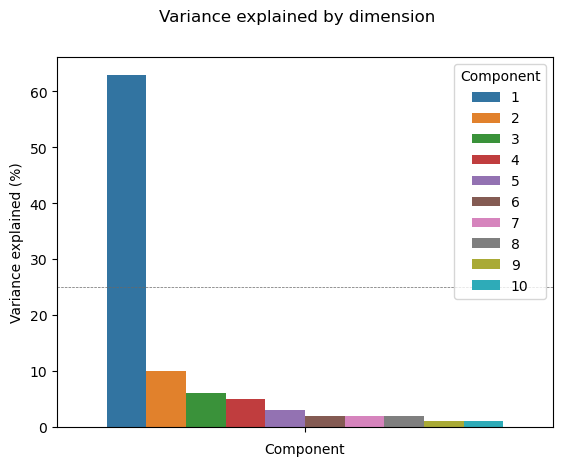

In [55]:
import seaborn as sns

g_comp = sns.barplot(hue = "Component", 
                y = "% variance explained",
                data = comp[0:10])
g_comp.set(ylabel = "Variance explained (%)")
g_comp.set(xlabel = "Component")
g_comp.figure.suptitle("Variance explained by dimension")
plt.axhline(y = 25, linewidth = .5, color = "dimgray", linestyle = "--") # 25 = 100 / 4 (nb of dimensions)

In [56]:
# Choose the principal components that explain at least 80% of the cumulative variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_to_keep = np.argmax(cumulative_variance >= 0.80) + 1 # +1 because my indices in my previous table start at 0
print(f" We retain {n_components_to_keep} main components to explain at least 80% of the variance.")

# We can test with 90% to see if it has an impact on our model

 We retain 4 main components to explain at least 80% of the variance.


We could have reached the threshold of 90% of variance explained (which is commonly done), but if we look closely at our principal components in our previous table, we notice that from 80% of cumulative variance, the variance explained by each axis is no longer sufficiently significant.


In [58]:
# Create a DataFrame of coefficients (loadings)

loadings = pd.DataFrame(
    pca.components_.T[:, :n_components_to_keep],  # We keep the selected components
    columns=[f'PC{i+1}' for i in range(n_components_to_keep)],
    index=data_1.columns  # Variable names
)
# These are the vectors of the 4 principal components retained from the previous code to represent 80% of the cumulative variance.
print(loadings)

             PC1       PC2       PC3       PC4
V-1     0.024434 -0.012530 -0.067670  0.063353
V-2     0.006141 -0.011148  0.004366 -0.007517
V-3     0.005661 -0.004614 -0.002180 -0.008749
V-4     0.013197 -0.010037  0.008645 -0.004236
V-5     0.075120 -0.010242  0.028593 -0.011205
...          ...       ...       ...       ...
V-25.4  0.105188 -0.012277  0.005096  0.029391
V-26.4  0.107716 -0.013819 -0.001284  0.011952
V-27.4  0.133077 -0.152112 -0.012951  0.036644
V-28.4  0.052416 -0.017263  0.443536 -0.164322
V-29.4  0.108344  0.023714 -0.009784 -0.012667

[103 rows x 4 columns]


In [59]:
# Sort variables by importance for PC1
top_variables_PC1 = abs(loadings.PC1).sort_values(ascending=False)
print(top_variables_PC1)

# Keep the 8 most influential variables for PC1
selected_variables_PC1 = top_variables_PC1.head(8).index.tolist()
print("Selected variables for PC1:")
print(selected_variables_PC1)
print(len(selected_variables_PC1))

# Sort variables by importance for PC2
top_variables_PC2 = abs(loadings.PC2).sort_values(ascending=False)
print(top_variables_PC2)

# Keep the 6 most influential variables for PC2
selected_variables_PC2 = top_variables_PC2.head(6).index.tolist()
print("Selected variables for PC2:")
print(selected_variables_PC2)
print(len(selected_variables_PC2))

# Sort variables by importance for PC3
top_variables_PC3 = abs(loadings.PC3).sort_values(ascending=False)
print(top_variables_PC3)

# Keep the 2 most influential variables for PC3
selected_variables_PC3 = top_variables_PC3.head(2).index.tolist()
print("Selected variables for PC3:")
print(selected_variables_PC3)
print(len(selected_variables_PC3))

# Sort variables by importance for PC4
top_variables_PC4 = abs(loadings.PC4).sort_values(ascending=False)
print(top_variables_PC4)

# Keep the 2 most influential variables for PC4
selected_variables_PC4 = top_variables_PC4.head(2).index.tolist()
print("Selected variables for PC4:")
print(selected_variables_PC4)
print(len(selected_variables_PC4))

V-23.2    0.182741
V-23.1    0.179838
V-23.3    0.179007
V-23.4    0.178669
V-23      0.178560
            ...   
V-4       0.013197
V-6       0.008518
V-2       0.006141
V-3       0.005661
V-7       0.000596
Name: PC1, Length: 103, dtype: float64
Selected variables for PC1:
['V-23.2', 'V-23.1', 'V-23.3', 'V-23.4', 'V-23', 'V-27.4', 'V-27.2', 'V-20']
8
V-11.2    0.245453
V-11.1    0.234084
V-11.3    0.230124
V-20.1    0.226119
V-20      0.225488
            ...   
V-26      0.002039
V-18.4    0.001100
V-13.3    0.000557
V-28.2    0.000371
V-6       0.000281
Name: PC2, Length: 103, dtype: float64
Selected variables for PC2:
['V-11.2', 'V-11.1', 'V-11.3', 'V-20.1', 'V-20', 'V-20.2']
6
V-28      0.443680
V-28.4    0.443536
V-18      0.322900
V-18.4    0.305650
V-28.2    0.229779
            ...   
V-26.4    0.001284
V-13.3    0.001074
V-29.3    0.000987
V-25.2    0.000739
V-25      0.000156
Name: PC3, Length: 103, dtype: float64
Selected variables for PC3:
['V-28', 'V-28.4']
2
V-20.3    0

In [60]:
# Selected variables
selected_variables = selected_variables_PC1 + selected_variables_PC2 + selected_variables_PC3 + selected_variables_PC4
# We erase the duplicates
selected_variables = list(dict.fromkeys(selected_variables))
print(selected_variables)
print(len(selected_variables))

['V-23.2', 'V-23.1', 'V-23.3', 'V-23.4', 'V-23', 'V-27.4', 'V-27.2', 'V-20', 'V-11.2', 'V-11.1', 'V-11.3', 'V-20.1', 'V-20.2', 'V-28', 'V-28.4', 'V-20.3']
16


In [61]:
# Compute the overall influence of each selected variable

def f(L):
    res = 0
    for i in range(len(L)):
        res = res + L[i]**2
    return res

loadings_numpy = loadings.to_numpy()
n, m = loadings.shape
loading_scores = []
for i in range(len(selected_variables)):
    for j in range(n):
        if selected_variables[i] == loadings.index[j]:
            loading_scores.append(f(loadings_numpy[j,:]))  # sum of squared contributions
print(len(loading_scores))

# Sort variables by importance

# Zip the two lists together
associes = list(zip(selected_variables, loading_scores))

# Sort by the score (index 1), in descending order
associes_tries = sorted(associes, key=lambda x: x[1], reverse=True)

# Unzip the sorted lists
selected_variables, loading_scores = zip(*associes_tries)

# Convert back to lists
selected_variables = list(selected_variables)
loading_scores = list(loading_scores)

print(selected_variables)
print(loading_scores)

16
['V-28', 'V-28.4', 'V-20.2', 'V-20.3', 'V-20.1', 'V-11.1', 'V-20', 'V-11.2', 'V-11.3', 'V-23.2', 'V-23.4', 'V-23.3', 'V-23.1', 'V-23', 'V-27.2', 'V-27.4']
[0.22684722960846163, 0.2267710750020481, 0.13776205698885957, 0.1317661356961828, 0.12779174459037895, 0.1127482220492964, 0.11107218308342766, 0.10506858151253604, 0.0773089447374497, 0.0772339883287204, 0.077035507585917, 0.07412761037239808, 0.06760755394334868, 0.06538522241102576, 0.05019435915814295, 0.04235818346276785]


In [62]:
n, m = X_train_scaled.shape
print(n,m)

k2 = len(selected_variables)
print(k2)

def select_ACP(X):
    n, m = X.shape
    X_ACP = np.array(np.zeros([k2, n]))
    print(X_ACP.shape)

    # Copy values from X only for selected_variables
    i = 0
    for i in range(len(selected_variables)):
        cpt = 0
        for column in data_1.columns:  # ❗ data_1 must be the DataFrame with original variable names
            if column == selected_variables[i]:
                for j in range(n):
                    X_ACP[i, j] = X.T[cpt, j]
                #print(cpt)
                break
            cpt = cpt + 1
    return X_ACP

X_train_ACP = select_ACP(X_train_scaled).T     
print(X_train_ACP.shape)
print(f"Variables that have significant variance are : {selected_variables}")

279 103
16
(16, 279)
(279, 16)
Variables that have significant variance are : ['V-28', 'V-28.4', 'V-20.2', 'V-20.3', 'V-20.1', 'V-11.1', 'V-20', 'V-11.2', 'V-11.3', 'V-23.2', 'V-23.4', 'V-23.3', 'V-23.1', 'V-23', 'V-27.2', 'V-27.4']


Variable selection via f_regression test

We use SelectKBest with the f_regression score function to rank features by their linear correlation with the target.

In [65]:
from sklearn.feature_selection import SelectKBest, f_regression

# Select top 15 features, arbitrry number of features
k = 15
selector_3 = SelectKBest(score_func=f_regression, k=k)
X_train_f_reg = selector_3.fit_transform(X_train_scaled, y_train_scaled.ravel())
print(X_train_f_reg.shape)
selected_features = data_1.columns[selector_3.get_support()].to_numpy()
print("Selected features :", selected_features)

(279, 15)
Selected features : ['V-5' 'V-8' 'V-25' 'V-25.1' 'V-26.1' 'V-13.2' 'V-25.2' 'V-26.2' 'V-13.3'
 'V-21.3' 'V-25.3' 'V-26.3' 'V-25.4' 'V-26.4' 'V-29.4']


Let's apply the same changes to the test

In [67]:
if select == 1:
    X_test_var_threshold = selector_1.transform(X_test_scaled)
    print(X_test_var_threshold.shape)
elif select == 2:
    X_test_ACP = select_ACP(X_test_scaled).T
    print(X_test_ACP.shape)
elif select == 3:
    X_test_f_reg = selector_3.transform(X_test_scaled)
    print(X_test_f_reg.shape)

(93, 15)


In [68]:
if select == 1:
    X_train_select = X_train_var_threshold
    X_test_select = X_test_var_threshold
elif select == 2:
    X_train_select = X_train_ACP
    X_test_select = X_test_ACP
elif select == 3:
    X_train_select = X_train_f_reg
    X_test_select = X_test_f_reg

# Third step: Modeling

We can now run regression methods on “X_train_select” and “y_train_scaled”.

**1) Linear and polynomial models**

Let's start with a linear model with a single variable/feature.

In [73]:
from sklearn.feature_selection import SelectKBest, f_regression

k_best = 1

if select == 1:
    # choose the best variable according to the f_regression test 
    # we can change for another test for example pearson correlation
    selector2 = SelectKBest(f_regression, k = k_best)
    X_train_select_1 = selector2.fit_transform(X_train_select, y_train_scaled.ravel())
    print(X_train_select_1.shape)
    
    selected_columns_2 = list(name_var_sign[selector2.get_support()])
    name_var_sign_1 = data_1[selected_columns_2].columns
    print("The best variable according to the f_regression test is :", name_var_sign_1[0])

elif select == 2:
    # choose the best variable according to the ACP
    def selectKBest_2(X):
        n, m = X.shape
        X_select = np.array(np.zeros([k_best,n])) # transposed matrix
        print(X_select.shape)

        for i in range(k_best):
            for j in range(n):
                X_select[i,j] = X.T[i,j]
        return X_select

    X_train_select_1 = selectKBest_2(X_train_select).T        
    print(X_train_select_1.shape)
    print("The best PCA variable is :", selected_variables[0])

elif select == 3:
    # choose the best variable according to the f_regression test 
    selector2 = SelectKBest(f_regression, k = k_best)
    X_train_select_1 = selector2.fit_transform(X_train_select, y_train_scaled.ravel())
    print(X_train_select_1.shape)
    
    selected_feature_1 = selected_features[selector2.get_support()]
    print("The best variable according to the f_regression test is :", selected_feature_1[0])

(279, 1)
The best variable according to the f_regression test is : V-8


In [74]:
# Apply the same changes to the test 
if select == 1:
    X_test_select_1 = selector2.transform(X_test_select)    
    print(X_test_select_1.shape)
elif select == 2:
    X_test_select_1 = selectKBest_2(X_test_select).T        
    print(X_test_select_1.shape)
elif select == 3:
    X_test_select_1 = selector2.transform(X_test_select)
    print(X_test_select_1.shape)

(93, 1)


**a) Linear model with only the best variable according to the f_regression or PCA test**

In [76]:
from sklearn.linear_model import LinearRegression

lin_reg_1 = LinearRegression()
lin_reg_1.fit(X_train_select_1, y_train_scaled)

LinearRegression()

(93, 1)
(93, 1)


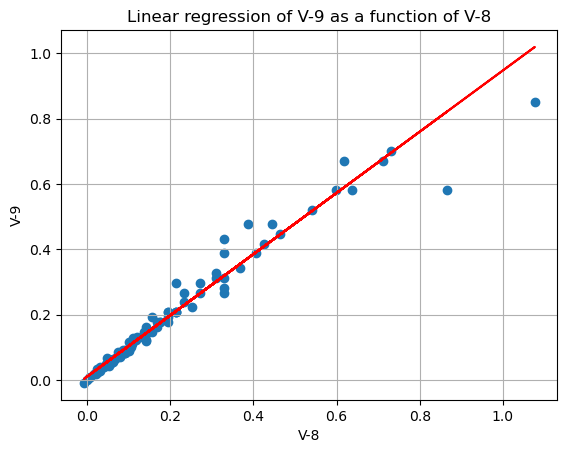

In [77]:
y_pred_scaled_1 = lin_reg_1.predict(X_test_select_1)

print(X_test_select_1.shape)
print(y_test_scaled.shape)

plt.scatter(X_test_select_1, y_test_scaled)
plt.plot(X_test_select_1, y_pred_scaled_1, color="r")
if select == 1:
    plt.xlabel(f"{name_var_sign_1[0]}")
    plt.ylabel("V-9")
    plt.title(f"Linear regression of V-9 as a function of {name_var_sign_1[0]}")
elif select == 2:
    plt.xlabel(f"{selected_variables[0]}")
    plt.ylabel("V-9")
    plt.title(f"Linear regression of V-9 as a function of {selected_variables[0]}")
elif select == 3:
    plt.xlabel(f"{selected_feature_1[0]}")
    plt.ylabel("V-9")
    plt.title(f"Linear regression of V-9 as a function of {selected_feature_1[0]}")
plt.grid(True)
plt.show()

Let's calculate its mean square error (MSE).

In [79]:
def MSE(y_pred, y_real):
    return np.sum(((y_pred - y_real)**2)) / len(y_pred)

In [80]:
from sklearn.metrics import mean_squared_error

y_pred_original_1 = inverse_normalisation(y_pred_scaled_1, choice)
print("y_pred_original top 5 values:", y_pred_original_1[:5])

MSE_linReg_1 = MSE(y_pred_original_1,y_test)
print("mean squared error :",MSE_linReg_1)
# We can check our formula with this :
print("mean squared error :",mean_squared_error(y_pred_original_1,y_test))
print("RMSE :",np.sqrt(MSE_linReg_1))

y_pred_original top 5 values: [[1032.46877532]
 [ 744.2660158 ]
 [ 372.00411807]
 [ 852.34205062]
 [ 468.07170458]]
mean squared error : 71199.42218441579
mean squared error : 71199.42218441579
RMSE : 266.8321985526031


Let's calculate the $R^2$ coefficient.

In [82]:
score_lin_reg_1 = lin_reg_1.score(X_test_select_1, y_test_scaled)
print("R-squared:", score_lin_reg_1)

R-squared: 0.9518055139197219


**b) Let's try a polynomial model.**

(279, 4)
(93, 4)


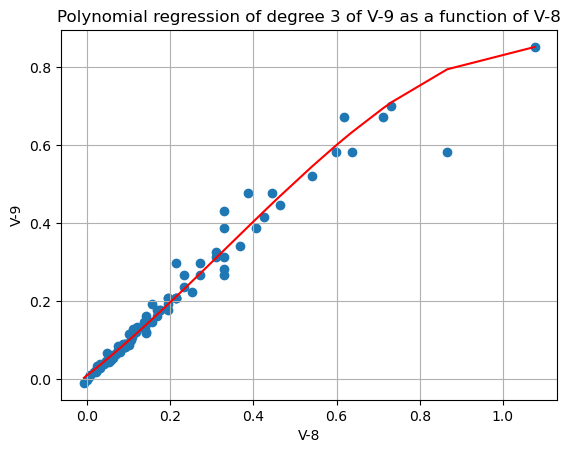

In [84]:
from sklearn.preprocessing import PolynomialFeatures

n=3 # degree

poly_n = PolynomialFeatures(degree=n)
poly_n.fit(X_train_select_1)
X_poly_1_train = poly_n.transform(X_train_select_1) # [1 , X, ..,X^n]
X_poly_1_test = poly_n.transform(X_test_select_1) # [1 , X, ..,X^n]
print(X_poly_1_train.shape)
print(X_poly_1_test.shape)

poly_n_reg = LinearRegression()
poly_n_reg.fit(X_poly_1_train, y_train_scaled)

y_pred_scaled_poly_1 = poly_n_reg.predict(X_poly_1_test)

# Sorting points for a smooth curve
sorted_indices = np.argsort(X_test_select_1[:, 0])
X_sorted = X_test_select_1[sorted_indices]
y_sorted = y_pred_scaled_poly_1[sorted_indices]

# Plotting the estimated polynomial
plt.scatter(X_test_select_1, y_test_scaled)
plt.plot(X_sorted, y_sorted, color='r')
if select == 1:
    plt.xlabel(f"{name_var_sign_1[0]}")
    plt.ylabel("V-9")
    plt.title(f"Polynomial regression of degree {n} of V-9 as a function of {name_var_sign_1[0]}")
elif select == 2:
    plt.xlabel(f"{selected_variables[0]}")
    plt.ylabel("V-9")
    plt.title(f"Polynomial regression of degree {n} of V-9 as a function of {selected_variables[0]}")
elif select == 3:
    plt.xlabel(f"{selected_feature_1[0]}")
    plt.ylabel("V-9")
    plt.title(f"Polynomial regression of degree {n} of V-9 as a function of {selected_feature_1[0]}")
plt.grid(True)
plt.show()


Let's try out different degrees of polynomial and display the error curves on the train and the test as a function of the degree of polynomial.

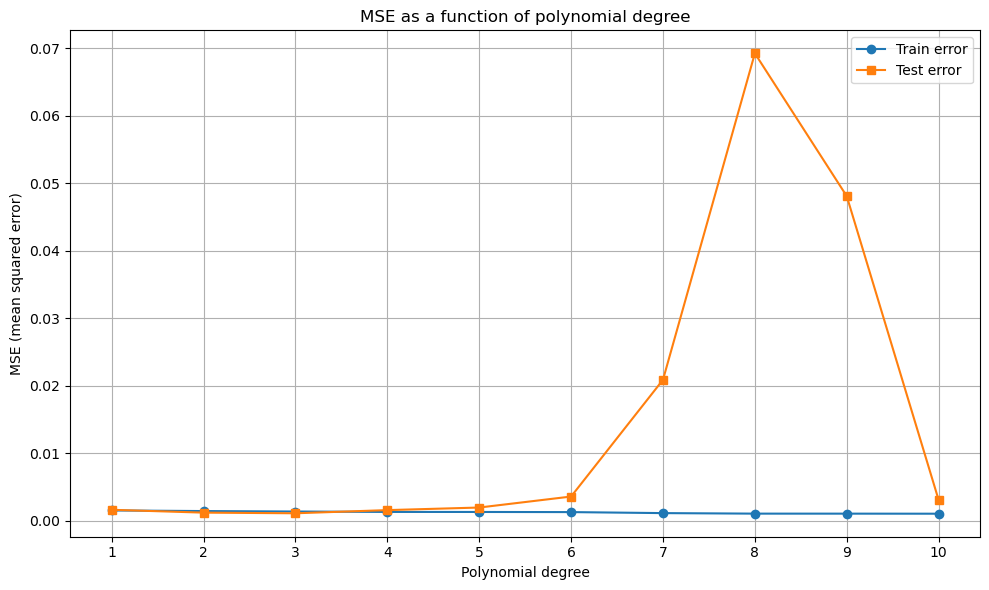

[0.0015908316896337204, 0.0011692991624908022, 0.0010749734574411467, 0.0015427658553207795, 0.0019246583053288595, 0.00355464839408623, 0.020855762458422803, 0.06924190206605116, 0.04807271073492167, 0.003036836264181764]


In [86]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

max_degree = 10
train_errors = []
test_errors = []

for degree in range(1, max_degree + 1):
    # Generation of polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_poly_train = poly.fit_transform(X_train_select_1)
    X_poly_test = poly.transform(X_test_select_1)

    # Regression
    model = LinearRegression()
    model.fit(X_poly_train, y_train_scaled)

    # Predictions
    y_train_pred = model.predict(X_poly_train)
    y_test_pred = model.predict(X_poly_test)

    # Errors
    train_mse = mean_squared_error(y_train_scaled, y_train_pred)
    test_mse = mean_squared_error(y_test_scaled, y_test_pred)

    train_errors.append(train_mse)
    test_errors.append(test_mse)

# plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, max_degree + 1), train_errors, label="Train error", marker='o')
plt.plot(range(1, max_degree + 1), test_errors, label="Test error", marker='s')
plt.xlabel("Polynomial degree")
plt.ylabel("MSE (mean squared error)")
plt.title("MSE as a function of polynomial degree")
plt.legend()
plt.grid(True)
plt.xticks(range(1, max_degree + 1))
plt.tight_layout()
plt.show()

print(test_errors)

In [87]:
print(rd_state, select, choice)

5 3 1


For rd_state = 5, select = 1, choice = 1, we see that the optimal degree is 3. After this, the model enters overfitting. The error on the train decreases but the error on the test increases.

In [89]:
optimal = test_errors.index(min(test_errors)) + 1 
print("The optimal degree is :", optimal)
            
poly = PolynomialFeatures(degree=optimal)
X_poly_train = poly.fit_transform(X_train_select_1)
X_poly_test = poly.transform(X_test_select_1)

model = LinearRegression()
model.fit(X_poly_train, y_train_scaled)

y_pred_scaled_optimal = model.predict(X_poly_test)

The optimal degree is : 3


Plot of our polynomial regression

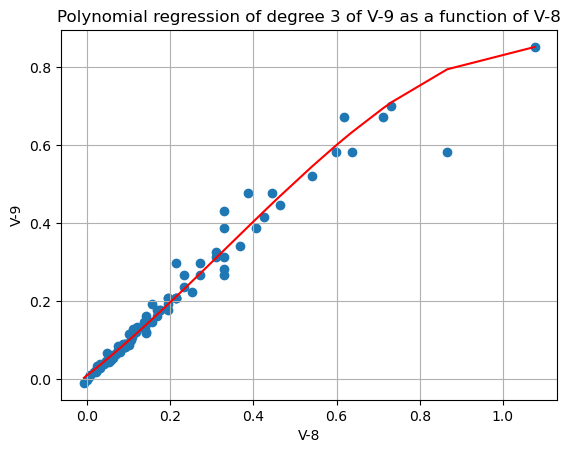

In [91]:
# Sorting points for a smooth curve
sorted_indices = np.argsort(X_test_select_1[:, 0])
X_sorted = X_test_select_1[sorted_indices]
y_sorted = y_pred_scaled_optimal[sorted_indices]

# Plotting the estimated polynomial
plt.scatter(X_test_select_1, y_test_scaled)
plt.plot(X_sorted, y_sorted, color='r')
if select == 1:
    plt.xlabel(f"{name_var_sign_1[0]}")
    plt.ylabel("V-9")
    plt.title(f"Polynomial regression of degree {optimal} of V-9 as a function of {name_var_sign_1[0]}")
elif select == 2:
    plt.xlabel(f"{selected_variables[0]}")
    plt.ylabel("V-9")
    plt.title(f"Polynomial regression of degree {optimal} of V-9 as a function of {selected_variables[0]}")
elif select == 3:
    plt.xlabel(f"{selected_feature_1[0]}")
    plt.ylabel("V-9")
    plt.title(f"Polynomial regression of degree {optimal} of V-9 as a function of {selected_feature_1[0]}")
plt.grid(True)
plt.show()

Let's calculate the mean square error (MSE) of our optimal polynomial model.

In [93]:
y_pred_optimal_poly = inverse_normalisation(y_pred_scaled_optimal, choice)
print("y_pred_original top 5 values:", y_pred_optimal_poly[:5])

MSE_polyFeat_1_optimal = MSE(y_pred_optimal_poly,y_test)
print("mean squared error :",MSE_polyFeat_1_optimal)
print("RMSE :",np.sqrt(MSE_polyFeat_1_optimal))

y_pred_original top 5 values: [[1009.48231758]
 [ 716.28112216]
 [ 356.48235847]
 [ 824.89025885]
 [ 447.04093875]]
mean squared error : 48111.61955858173
RMSE : 219.34361070836263


Let's calculate the $R^2$ coefficient.

In [95]:
score_polyFeat_1_optimal = model.score(X_poly_test, y_test_scaled)
print("R-squared :", score_polyFeat_1_optimal)

R-squared : 0.9674335169025681


**c) Let's run a linear model on all the variables of "X_train_select"**

In [97]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train_select, y_train_scaled)

LinearRegression()

In [98]:
print(f'coef(without intercept) : {lin_reg.coef_} and intercept : { lin_reg.intercept_}')

coef(without intercept) : [[ 0.05098948  0.94566395  0.48043705  0.16088081 -1.37740507  0.01472842
  -0.61702556  1.58736584 -1.18117285 -0.13776938  0.50079316 -0.56795837
   0.48419153  0.20319936  0.29478284]] and intercept : [0.01428103]


(-0.05194319880418535,
 1.106192168473824,
 -0.05726500617468605,
 1.1008703611033235)

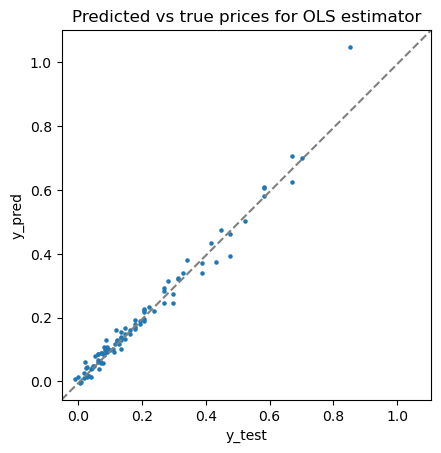

In [99]:
y_pred_scaled = lin_reg.predict(X_test_select)

fig, ax = plt.subplots()
ax.scatter(y_test_scaled, y_pred_scaled, s = 5)
ax.plot([0, 1], [0, 1],transform=ax.transAxes, ls = '--', c = 'gray')
ax.set_xlabel('y_test')
ax.set_ylabel('y_pred')
ax.set_title('Predicted vs true prices for OLS estimator')
ax.axis('square')

We have obtained a prediction on the scaled data and we want to get back to the initial data for a better interpretation of the results.

In [101]:
y_pred_original = inverse_normalisation(y_pred_scaled, choice)
print("y_pred_original top 5 values:", y_pred_original[:5])

y_pred_original top 5 values: [[1010.68076879]
 [ 827.29444177]
 [ 411.57525278]
 [ 718.58444412]
 [ 438.60029737]]


MSE

In [103]:
print(y_pred_original.shape)
print(y_test.shape)

MSE_linReg = MSE(y_pred_original,y_test)
print("mean squared error :",MSE_linReg)
print("RMSE :",np.sqrt(MSE_linReg))

(93, 1)
(93, 1)
mean squared error : 39957.15378381714
RMSE : 199.89285575982234


Let's calculate the $R^2$ coefficient.

In [105]:
score_lin_reg = lin_reg.score(X_test_select, y_test_scaled)
print("R-squared :", score_lin_reg)

R-squared : 0.9729532286532627


**2) Linear regularisation models**

We will now run Ridges and Lasso regressions using Cross Validation.

Let's start with a Cross Validation Ridge.

In [109]:
from sklearn.linear_model import RidgeCV

alpha_s = np.logspace(-4,6,50)
print(X_train_select.shape)
print(y_train_scaled.shape)
print(y_train_scaled.ravel().shape)

ridgeCV = RidgeCV(alphas = alpha_s, store_cv_results=True) # store_cv_values depend on the version
ridgeCV.fit(X_train_select, y_train_scaled.ravel())
ridgeCV.cv_results_.shape  # cv_values_


(279, 15)
(279, 1)
(279,)


(279, 50)

We get 279 scores because we use Leave-One-Out Cross-Validation.

We compute the mean of the scores for each alpha.

In [112]:
alpha_score = ridgeCV.cv_results_.mean(axis = 0) # cv_values_
print(alpha_score)
alpha_score.shape

[0.00108793 0.00108724 0.00108639 0.00108548 0.00108467 0.00108417
 0.00108414 0.0010847  0.00108597 0.00108829 0.00109256 0.00110048
 0.00111457 0.00113794 0.00117387 0.00122548 0.00129604 0.0013921
 0.00153109 0.00175153 0.00212154 0.00274258 0.00374333 0.0052436
 0.00727134 0.00968413 0.01220207 0.01456089 0.01665373 0.01855542
 0.02043404 0.02241144 0.0244615  0.02642669 0.02813134 0.02947883
 0.03046791 0.03115566 0.03161635 0.03191735 0.03211086 0.03223398
 0.03231181 0.03236079 0.03239155 0.03241082 0.03242289 0.03243044
 0.03243517 0.03243812]


(50,)

Plot of score as a function of different alpha values.

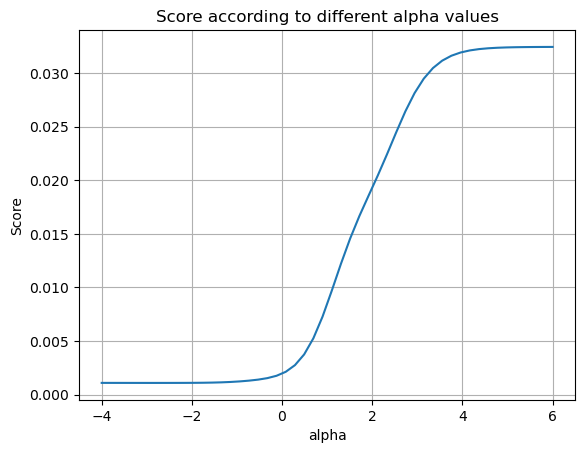

In [114]:
plt.plot(np.log10(alpha_s),alpha_score)
plt.xlabel("alpha")
plt.ylabel("Score")
plt.title("Score according to different alpha values")
plt.grid(True)
plt.show()

We will choose alpha_R = ridgeCV.alpha_ . This is the argmin.

In [116]:
alpha_R = ridgeCV.alpha_

Let's move on to a Cross Validation Lasso.

In [118]:
from sklearn.linear_model import LassoCV

if loo == 1:
    lassoCV = LassoCV(n_alphas=50, cv = len(y_train_scaled))
if loo == 2:  
    lassoCV = LassoCV(n_alphas=50)
lassoCV.fit(X_train_select, y_train_scaled.ravel())
lassoCV.mse_path_.shape

C:\Users\tbout\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:683: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.0011290940602377564, tolerance: 0.0008860886783746002
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\tbout\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:683: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.0008594058541764871, tolerance: 0.0008444039461668012
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\tbout\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:683: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.0009208010031930003, tolerance: 0.000875433991522622
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\tbout\anaconda3\Lib\site-packages\sklearn\linear_model\_coordi

(50, 279)

We have k = 5 folds by default and in this case the shape is (50 , 5) and not (5 , 50) beware.

We compute the mean of the scores for each alpha.

In [121]:
alpha_score=lassoCV.mse_path_.mean(axis=1) 
alpha_score.shape

(50,)

Plot of score as a function of different alpha values.

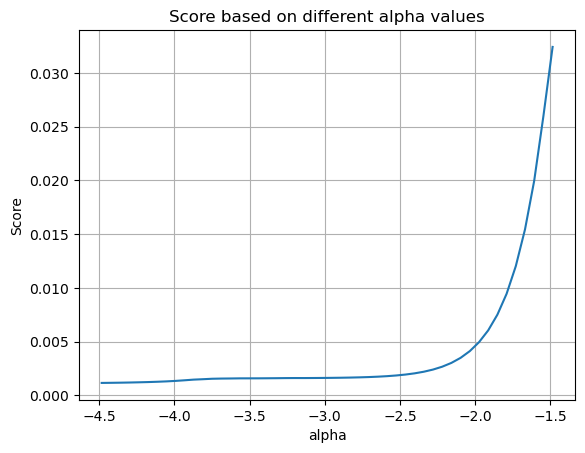

In [123]:
alphas=lassoCV.alphas_
plt.plot(np.log10(alphas),alpha_score)
plt.xlabel("alpha")
plt.ylabel("Score")
plt.title("Score based on different alpha values")
plt.grid(True)
plt.show()

We will choose alpha_L = lassoCV.alpha_ . This is the argmin.

In [125]:
alpha_L = lassoCV.alpha_

**a) Ridge with the optimal alpha**

In [127]:
from sklearn.linear_model import Ridge

ridgeCV_best_alpha = Ridge(alpha_R, fit_intercept=True)
ridgeCV_best_alpha.fit(X_train_select,y_train_scaled)

print(f'coef(without intercept) : {ridgeCV_best_alpha.coef_} and intercept : { ridgeCV_best_alpha.intercept_}')

coef(without intercept) : [[ 0.05091362  0.94741109  0.41427946  0.0311888  -0.75289449 -0.15309412
  -0.18358451  0.70610249 -1.0680948  -0.15163295  0.29150068 -0.01801738
   0.44424367 -0.03424814  0.30365357]] and intercept : [0.01501235]


(-0.05194319880418535,
 1.1037313958348791,
 -0.05332325202531889,
 1.1023513426137457)

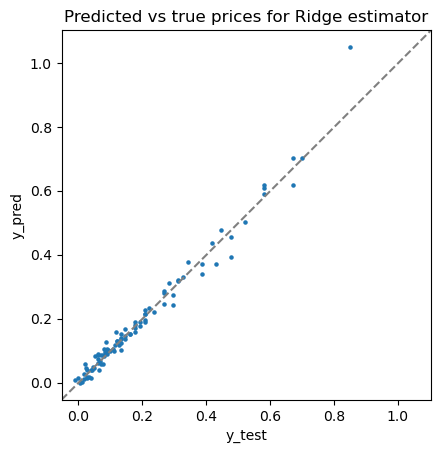

In [128]:
y_pred_RigdeReg = ridgeCV_best_alpha.predict(X_test_select)

fig, ax = plt.subplots()
ax.scatter(y_test_scaled, y_pred_RigdeReg, s = 5)
ax.plot([0, 1], [0, 1],transform=ax.transAxes, ls = '--', c = 'gray')
ax.set_xlabel('y_test')
ax.set_ylabel('y_pred')
ax.set_title('Predicted vs true prices for Ridge estimator')
ax.axis('square')

**b) Lasso with the optimal alpha**

In [130]:
from sklearn.linear_model import Lasso

lassoCV_best_alpha = Lasso(alpha_L)
lassoCV_best_alpha.fit(X_train_select,y_train_scaled)

print(f'coef(without intercept) : {lassoCV_best_alpha.coef_} and intercept : { lassoCV_best_alpha.intercept_}')

coef(without intercept) : [ 0.04135592  0.94850578  0.18680552  0.         -0.         -0.2773579
  0.01221167  0.         -0.83644977 -0.12827049  0.39885576  0.03292661
  0.20083832  0.          0.23784044] and intercept : [0.01951912]


C:\Users\tbout\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.966e-03, tolerance: 8.987e-04
  model = cd_fast.enet_coordinate_descent(


(-0.05194319880418535,
 1.0921193046763624,
 -0.04896725205852058,
 1.0950952514220273)

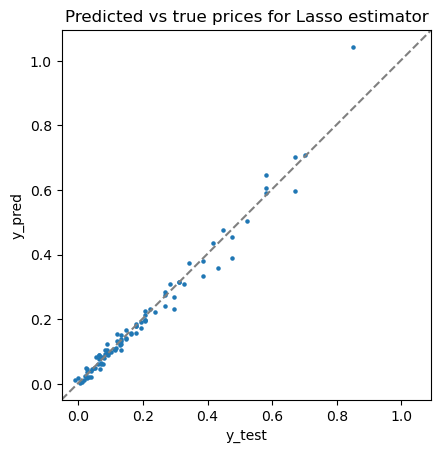

In [131]:
y_pred_LassoReg = lassoCV_best_alpha.predict(X_test_select)

fig, ax = plt.subplots()
ax.scatter(y_test_scaled, y_pred_LassoReg, s = 5)
ax.plot([0, 1], [0, 1],transform=ax.transAxes, ls = '--', c = 'gray')
ax.set_xlabel('y_test')
ax.set_ylabel('y_pred')
ax.set_title('Predicted vs true prices for Lasso estimator')
ax.axis('square')

**c) Calculation of the best alpha with a "BIC criterion".**

In [133]:
from sklearn.linear_model import LassoLarsIC
lassoBIC=LassoLarsIC(criterion='bic')
lassoBIC.fit(X_train_select,y_train_scaled.ravel())
print("best alpha chosen by BIC criterion :",lassoBIC.alpha_)
print("best alpha chosen by CV :",alpha_L)
print(lassoBIC.coef_)

best alpha chosen by BIC criterion : 4.461335280989136e-06
best alpha chosen by CV : 3.278386777508944e-05
[ 0.05087044  0.94808347  0.39289133  0.         -0.72094252 -0.14830089
  0.          0.61422588 -1.07079378 -0.14355641  0.15652307  0.
  0.45341025  0.          0.29722196]


Comparison between predicted price and true price for "LassoBIC" estimator :

(-0.05194319880418535,
 1.1001872918883633,
 -0.05121510981583047,
 1.1009153808767183)

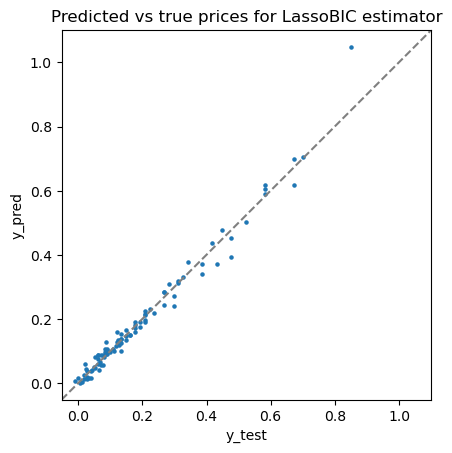

In [135]:
y_pred_BIC = lassoBIC.predict(X_test_select)

fig, ax = plt.subplots()
ax.scatter(y_test_scaled, y_pred_BIC, s = 5)
ax.plot([0, 1], [0, 1], transform=ax.transAxes, ls = '--', c = 'gray')
ax.set_xlabel('y_test')
ax.set_ylabel('y_pred')
ax.set_title('Predicted vs true prices for LassoBIC estimator')
ax.axis('square')

**Comparison between OLS, RidgeCV, LassoCV, LassoBIC**

We compute the MSE for these 4 different estimators (OLS, RidgeCV, LassoCV, LassoBIC).

In [138]:
y_pred_OLS = inverse_normalisation(y_pred_scaled, choice)
y_pred_Ridge = inverse_normalisation(y_pred_RigdeReg, choice)
y_pred_Lasso = inverse_normalisation(y_pred_LassoReg, choice).reshape(-1,1)
y_pred_LassoBIC = inverse_normalisation(y_pred_BIC, choice).reshape(-1,1)

print(y_test.shape) # The prediction must have the same shape

MSE_OLS = MSE(y_pred_OLS,y_test)
MSE_Ridge = MSE(y_pred_Ridge,y_test)
MSE_Lasso = MSE(y_pred_Lasso,y_test)
MSE_LassoBIC = MSE(y_pred_LassoBIC,y_test)

print("MSE :")
print(np.round(MSE_OLS,2),"OLS")
print(np.round(MSE_Ridge,2),"Ridge")
print(np.round(MSE_Lasso,2),"Lasso")
print(np.round(MSE_LassoBIC,2),"LassoBIC")
print("RMSE :")
print(np.round(np.sqrt(MSE_OLS),3),"OLS")
print(np.round(np.sqrt(MSE_Ridge),3),"Ridge")
print(np.round(np.sqrt(MSE_Lasso),3),"Lasso")
print(np.round(np.sqrt(MSE_LassoBIC),3),"LassoBIC")

(93, 1)
MSE :
39957.15 OLS
40599.53 Ridge
42485.19 Lasso
40167.58 LassoBIC
RMSE :
199.893 OLS
201.493 Ridge
206.119 Lasso
200.419 LassoBIC


We compute the $R^2$ coefficient for these 4 different estimators (OLS, RidgeCV, LassoCV, LassoBIC).

In [140]:
score_lin_reg = lin_reg.score(X_test_select, y_test_scaled)
score_Ridge = ridgeCV_best_alpha.score(X_test_select, y_test_scaled)
score_Lasso = lassoCV_best_alpha.score(X_test_select, y_test_scaled)
score_BIC = lassoBIC.score(X_test_select, y_test_scaled)

print("R-squared coefficient :")
print(np.round(score_lin_reg,5),"OLS")
print(np.round(score_Ridge,5),"Ridge")
print(np.round(score_Lasso,5),"Lasso")
print(np.round(score_BIC,5),"LassoBIC")

R-squared coefficient :
0.97295 OLS
0.97252 Ridge
0.97124 Lasso
0.97281 LassoBIC


We display the boxplot of the absolute errors for each estimator. 

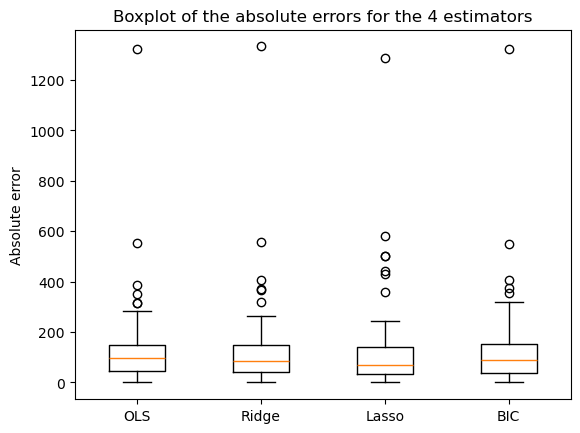

In [142]:
def absolute_error(y_pred, y_real):
    return (abs(y_pred - y_real))


err_OLS = absolute_error(y_pred_OLS,y_test).ravel()
err_Ridge = absolute_error(y_pred_Ridge,y_test).ravel()
err_Lasso = absolute_error(y_pred_Lasso,y_test).ravel()
err_BIC = absolute_error(y_pred_LassoBIC,y_test).ravel()

L = [err_OLS, err_Ridge, err_Lasso, err_BIC]

plt.boxplot(L)
plt.title('Boxplot of the absolute errors for the 4 estimators')
plt.ylabel('Absolute error')
plt.xticks([1, 2, 3, 4], ["OLS", "Ridge", "Lasso", "BIC"])
plt.show()

For most of the possible combinations of our parameters, we note that the four previous methods give RMSEs and $R^2$ coefficients that are very close to each other. We can therefore state that the LassoCV and LassoBIC models are preferable since they provide a prediction that is almost similar to the others and have better interpretability because they have removed certain variables by setting their coefficients to zero. Their explanations are therefore simpler.

In [144]:
print(select, choice, rd_state, loo)

3 1 5 1


Remark : Linear regression works (very) well for select = 1, choice = (2) or 1, rd_state = 5, loo = 1.
They also work very well for select = 3.

We choose Lasso with leave-one-out for parts 4 and 5. Set loo = 1 and rerun the code.

**3) Poisson Regression**

In [148]:
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import r2_score

if choice == 1:
    print(X_train_select.shape)
    print(y_train_scaled.shape)
    
    Pois_reg = PoissonRegressor()
    Pois_reg.fit(X_train_select, y_train_scaled.ravel())
    y_pred_Pois_reg_scaled = Pois_reg.predict(X_test_select)
    y_pred_Pois_reg = inverse_normalisation(y_pred_Pois_reg_scaled, choice).reshape(-1,1)
    print(y_pred_Pois_reg.shape)
    print(y_test.shape)

    MSE_Pois_reg = MSE(y_pred_Pois_reg,y_test)
    print("MSE :", MSE_Pois_reg)
    print("RMSE :", np.sqrt(MSE_Pois_reg))
    score_Pois_reg = r2_score(y_test, y_pred_Pois_reg)
    print("R-squared coefficient :", score_Pois_reg)

(279, 15)
(279, 1)
(93, 1)
(93, 1)
MSE : 1324067.556973357
RMSE : 1150.681344670781
R-squared coefficient : 0.10374616132955561


Poisson regression does not work well in our case and we get errors if we use RobustScaler.

**4) Models with interaction**

PolyFeat with interaction between variables

We only keep the variables associated to a non-nul coefficient in the LassoCV

In [153]:
def non_nul_coefficient_lassoCV(lassoCV_best_alpha):
    L = lassoCV_best_alpha.coef_
    name_var_non_nul = []
    for i in range (len(L)):
        if L[i] != 0:
            if select == 1:
                name_var_non_nul.append(name_var_sign[i])
            elif select == 2:
                name_var_non_nul.append(selected_variables[i])
            elif select == 3:
                name_var_non_nul.append(selected_features[i])
    return name_var_non_nul

name_var_non_nul = non_nul_coefficient_lassoCV(lassoCV_best_alpha)
print(f"The variables associated to a non-nul coefficient in the lassoCV are: {name_var_non_nul}")

The variables associated to a non-nul coefficient in the lassoCV are: ['V-5', 'V-8', 'V-25', 'V-13.2', 'V-25.2', 'V-13.3', 'V-21.3', 'V-25.3', 'V-26.3', 'V-25.4', 'V-29.4']


We create the data frame with only the variables in "name_var_non_nul".

In [155]:
cols_to_exclude = [col for col in data_1.select_dtypes(include=["number"]).columns if col not in name_var_non_nul]
data_2 = data_1.drop(cols_to_exclude, axis=1)
data_2.head(5)

,V-5,V-8,V-25,V-13.2,V-25.2,V-13.3,V-21.3,V-25.3,V-26.3,V-25.4,V-29.4
0,190,1200,67.81,59.40,63.69,57.65,746.800000,62.78,56.45,60.74,601988.1
1,400,2900,105.52,98.64,98.12,96.49,1294.200000,95.35,94.34,90.95,929027.1
2,100,630,45.91,40.21,41.79,39.43,574.600000,41.03,33.37,38.70,377828.6
3,20,140,11.62,6.97,10.17,5.44,180.371507,9.91,8.85,9.73,122031.7
4,410,5000,158.63,147.44,140.90,141.34,2451.200000,136.56,138.80,136.60,1734973.5


We create our new X matrix.

In [157]:
X_new = data_2[name_var_non_nul].to_numpy()
print(X_new.shape)

(372, 11)


Split the dataset into a training set and a test set, keeping 25% of the data for the test set with the same random state and repartition as before

In [159]:
from sklearn.model_selection import train_test_split

X_train_new, X_test_new = train_test_split(X_new,test_size= test_size, random_state=rd_state)
print(X_train_new.shape)
print(X_test_new.shape)

(279, 11)
(93, 11)


Standardisation

In [161]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler

# Initialisation of scaler
if choice == 1:
    scaler = MinMaxScaler()
    # Save the min/max of the covariables on the train to denormalised after
    X_min_new = X_train_new.min(axis=0).reshape(1,-1)
    X_max_new = X_train_new.max(axis=0).reshape(1,-1)
    print(X_min_new.shape)
    print(X_max_new.shape)
elif choice == 2:
    scaler = RobustScaler()

# Apply the scaling on the data
X_train_new_scaled = scaler.fit_transform(X_train_new)
print(X_train_new_scaled.shape)
X_test_new_scaled = scaler.transform(X_test_new)
print(X_test_new_scaled.shape)

(1, 11)
(1, 11)
(279, 11)
(93, 11)


PolyFeat with interaction between variables

In [163]:
from sklearn.preprocessing import PolynomialFeatures

print(X_train_new_scaled.shape)

n = 2 # degree

poly = PolynomialFeatures(degree=n, interaction_only = True)
poly.fit(X_train_new_scaled)
X_poly_train = poly.transform(X_train_new_scaled)
X_poly_test = poly.transform(X_test_new_scaled)
print("number of features :", X_poly_train.shape[1])

poly_reg = LinearRegression()
poly_reg.fit(X_poly_train, y_train_scaled)

y_pred_scaled_poly = poly_reg.predict(X_poly_test)

(279, 11)
number of features : 67


MSE and $R^2$

In [165]:
y_pred_poly_interaction = inverse_normalisation(y_pred_scaled_poly, choice)
print("5 first values of y_pred_poly_interaction:", y_pred_poly_interaction[:5])
print(y_pred_poly_interaction.shape)
print(y_test.shape)

MSE_poly_interaction = MSE(y_pred_poly_interaction, y_test)
print("MSE :", MSE_poly_interaction)
print("RMSE :", np.sqrt(MSE_poly_interaction))

score_poly_interaction = poly_reg.score(X_poly_test, y_test_scaled)
print("R-squared :", score_poly_interaction)

5 first values of y_pred_poly_interaction: [[993.61572266]
 [907.05078125]
 [245.56396484]
 [748.62060547]
 [351.72851562]]
(93, 1)
(93, 1)
MSE : 125980.8623718959
RMSE : 354.9378288826029
R-squared : 0.9147242669717519


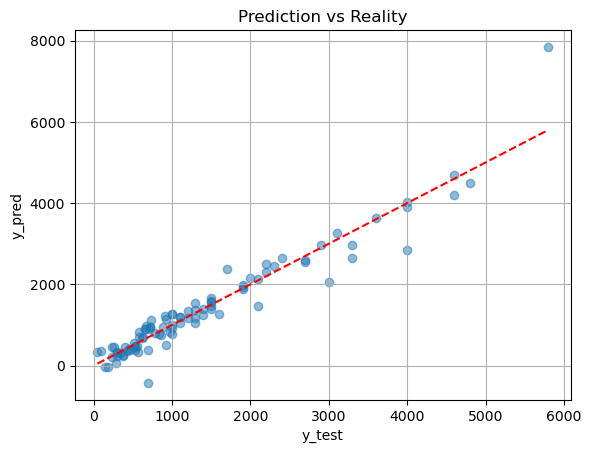

In [166]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_poly_interaction, alpha=0.5)
plt.xlabel("y_test")
plt.ylabel("y_pred")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
plt.title("Prediction vs Reality")
plt.grid(True)

Remark: Works well with rd_state = 47, select = 1 and choice = 1.

**5) Model of higher dimension**

number of features : 12
number of features : 78
number of features : 364
number of features : 1365
number of features : 4368


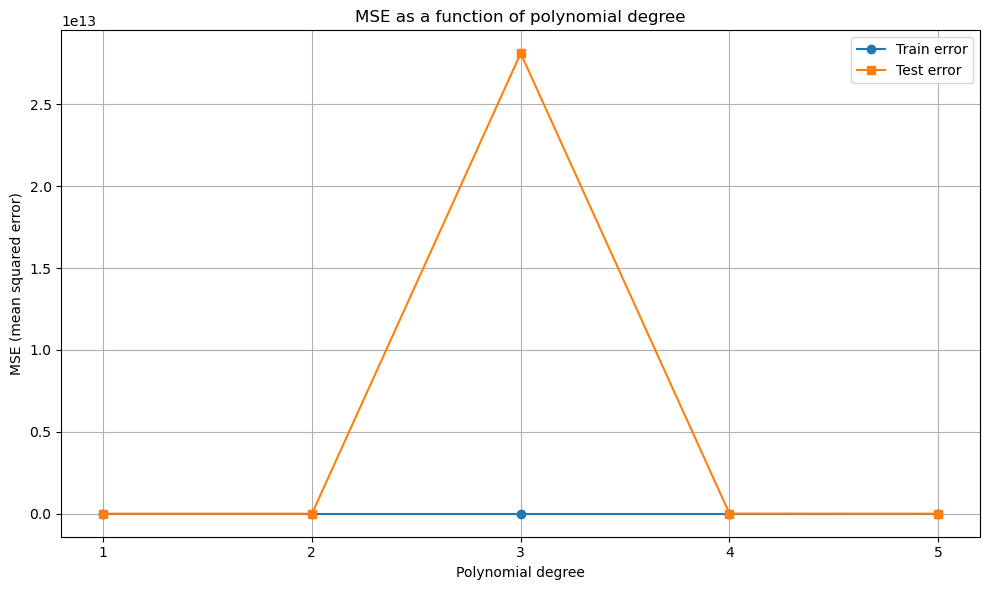

[0.0009521677703565667, 0.0031044448124775787, 28114558136624.633, 5233308966.679513, 5116.945465792304]


In [169]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

max_degree = 5
train_errors = []
test_errors = []

for degree in range(1, max_degree + 1):
    # Generation of polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_poly_train = poly.fit_transform(X_train_new_scaled)
    X_poly_test = poly.transform(X_test_new_scaled)
    print("number of features :", X_poly_train.shape[1])
    
    # Regression
    model = LinearRegression()
    model.fit(X_poly_train, y_train_scaled)

    # Predictions
    y_train_pred = model.predict(X_poly_train)
    y_test_pred = model.predict(X_poly_test)

    # Errors
    train_mse = mean_squared_error(y_train_scaled, y_train_pred)
    test_mse = mean_squared_error(y_test_scaled, y_test_pred)

    train_errors.append(train_mse)
    test_errors.append(test_mse)

# plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, max_degree + 1), train_errors, label="Train error", marker='o')
plt.plot(range(1, max_degree + 1), test_errors, label="Test error", marker='s')
plt.xlabel("Polynomial degree")
plt.ylabel("MSE (mean squared error)")
plt.title("MSE as a function of polynomial degree")
plt.legend()
plt.grid(True)
plt.xticks(range(1, max_degree + 1))
plt.tight_layout()
plt.show()

print(test_errors)

In [170]:
optimal_degree = test_errors.index(min(test_errors)) + 1
print("The optimal degree is :", optimal_degree)

poly = PolynomialFeatures(degree=optimal_degree)
X_poly_train = poly.fit_transform(X_train_new_scaled)
X_poly_test = poly.transform(X_test_new_scaled)
print("number of features :", X_poly_train.shape[1])

model = LinearRegression()
model.fit(X_poly_train, y_train_scaled)

y_pred_scaled_polyFeat_2 = model.predict(X_poly_test)

The optimal degree is : 1
number of features : 12


MSE and $R^2$

In [172]:
y_pred_polyFeat_2 = inverse_normalisation(y_pred_scaled_polyFeat_2, choice)
print("y_pred_polyFeat_2 top 5 values:", y_pred_polyFeat_2[:5])

MSE_polyFeat_2 = MSE(y_pred_polyFeat_2, y_test)
print("mean squared error :",MSE_polyFeat_2)
print("RMSE :",np.sqrt(MSE_polyFeat_2))

score_polyFeat_2 = model.score(X_poly_test, y_test_scaled)
print("R-squared :", score_polyFeat_2)

y_pred_polyFeat_2 top 5 values: [[1041.56366122]
 [ 807.4714131 ]
 [ 346.77782016]
 [ 823.77124398]
 [ 433.69820548]]
mean squared error : 42615.315946855524
RMSE : 206.43477407369022
R-squared : 0.9711539337231178


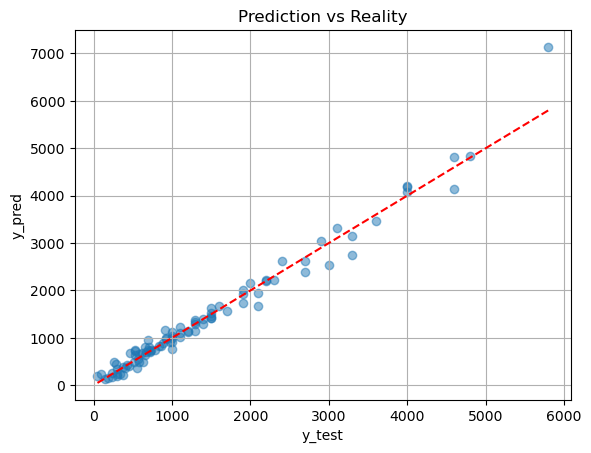

In [173]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_polyFeat_2, alpha=0.5)
plt.xlabel("y_test")
plt.ylabel("y_pred")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
plt.title("Prediction vs Reality")
plt.grid(True)

We can see that the previous models are very sensitive to the random_state used. Furthermore, increasing the dimension and/or adding interactions are not necessarily good ideas, as they often degrade our RMSE and make the model more complex. We would therefore like to look at other models.

# Correlation studies

We are going to see whether there is correlation between features. This can pose a challenge for machine learning models, as highly correlated features may provide redundant information, potentially complicating the training process and leading to overfitting. 

The VIF (Variance Inflation Factor) measures multicollinearity among the explanatory variables in a regression model.
When the VIF is greater than 10, it indicates a very high correlation. A VIF above 5 suggests moderate correlation.

In [178]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# Adding a constant to the model
X_with_const = sm.add_constant(data_1)

# Computing the VIF for each variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X_with_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_with_const.values, i)
                   for i in range(X_with_const.shape[1])]

high_vif = vif_data[vif_data["VIF"] > 10]
print("number of variables with a high VIF:", len(high_vif))

C:\Users\tbout\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1783: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
C:\Users\tbout\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


number of variables with a high VIF: 98


We notice that all or almost all the features are highly correlated. It is thus important to use models that are robust to multicollinearity.

Let's see the correlation between the features and the target.

highly correlated variables V-9 (|corr| > 0.6) :
V-8       0.976432
V-5       0.784986
V-25.3    0.617012
V-25.4    0.615417
V-26.4    0.614735
V-26.3    0.613503
V-13.3    0.611318
V-25.2    0.611286
V-26.2    0.611185
V-21.3    0.609523
V-25.1    0.608775
V-26.1    0.608620
V-25      0.608333
V-26      0.607252
V-29.4    0.606571
V-13.4    0.606079
V-13.2    0.604537
V-15      0.601155
dtype: float64


C:\Users\tbout\AppData\Local\Temp\ipykernel_19960\3698949917.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=selected_features.values, y=selected_features.index, palette='coolwarm', orient='h')


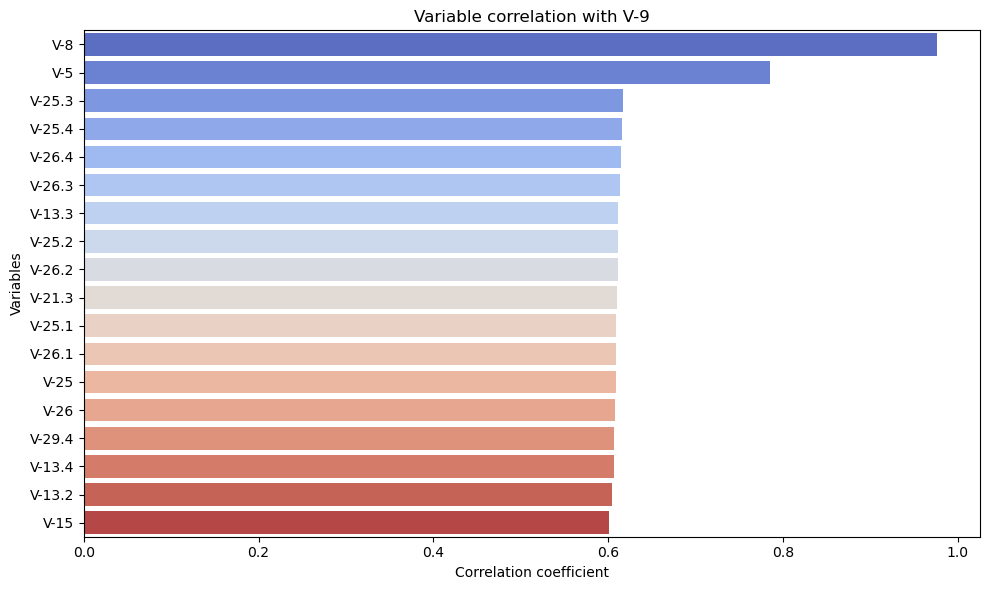

In [181]:
import seaborn as sns

target = data['V-9']
correlations = data_1.corrwith(target)

# We keep features highly correlated with V-9
selected_features = correlations[(correlations > 0.6) | (correlations < -0.6)].sort_values(ascending=False)

print("highly correlated variables V-9 (|corr| > 0.6) :")
print(selected_features)

# Barplot to vizualise
plt.figure(figsize=(10, 6))
sns.barplot(x=selected_features.values, y=selected_features.index, palette='coolwarm', orient='h')
plt.title("Variable correlation with V-9")
plt.xlabel("Correlation coefficient")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

We observe that V8 (unit price at the beginning of the project) and V5 (estimated cost at the beginning of the project) show a strong positive correlation with V9 (actual selling price), with Pearson correlation coefficients greater than 0.78. This indicates that as the unit price or estimated cost increases, the actual selling price also tends to increase which is consistent and expected in this context.
There are also many other variables with correlation coefficients between 0.6 and 0.7.

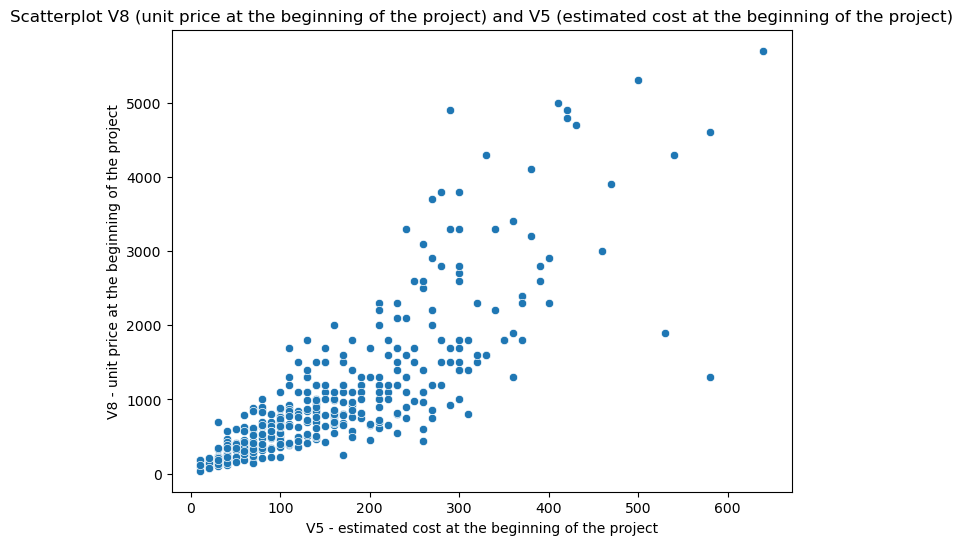

In [183]:
# scatterplot to visualize the relationship between V-5 and V-8 just for information
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data_1, x='V-5', y='V-8')
plt.title('Scatterplot V8 (unit price at the beginning of the project) and V5 (estimated cost at the beginning of the project)')
plt.xlabel('V5 - estimated cost at the beginning of the project')
plt.ylabel('V8 - unit price at the beginning of the project')
plt.show()

Given this information, it appears that due to the correlation between variables, linear and polynomial regression models may be less suitable than the following models:

**6) K-NN**

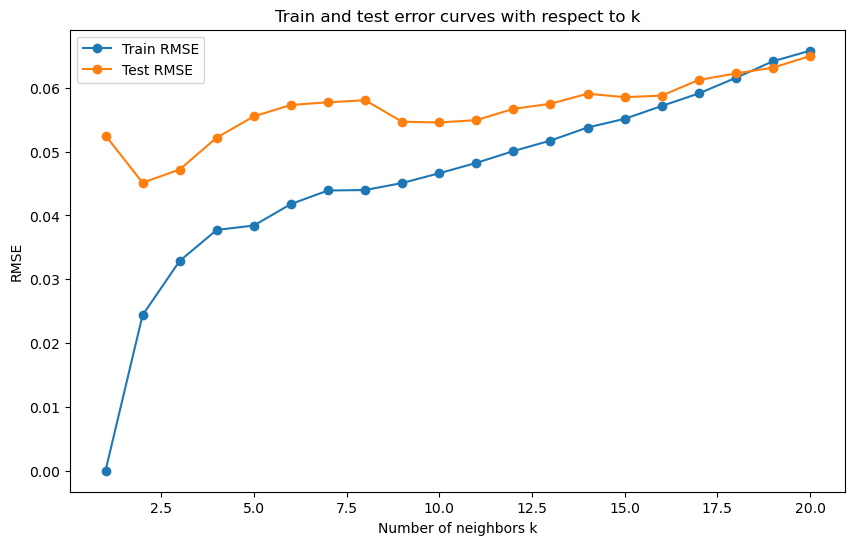

In [186]:
from sklearn.neighbors import KNeighborsRegressor

# We try different values of k from 1 to 20 (number of neighbors)
# For each value of k, we compare the training and test errors

k_values = list(range(1, 21))
train_errors = []
test_errors = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    
    knn.fit(X_train_select, y_train_scaled)
    
    y_train_pred = knn.predict(X_train_select)
    y_test_pred = knn.predict(X_test_select)
    
    train_rmse = root_mean_squared_error(y_train_scaled, y_train_pred)
    test_rmse = root_mean_squared_error(y_test_scaled, y_test_pred)
    
    train_errors.append(train_rmse)
    test_errors.append(test_rmse)

plt.figure(figsize=(10,6))
plt.plot(k_values, train_errors, label='Train RMSE', marker='o')
plt.plot(k_values, test_errors, label='Test RMSE', marker='o')
plt.xlabel('Number of neighbors k')
plt.ylabel('RMSE')
plt.title('Train and test error curves with respect to k')
plt.legend()
plt.show()

In [187]:
k_best = test_errors.index(min(test_errors)) + 1 
print("The optimal K is :", k_best)

The optimal K is : 2


In [188]:
knn_final = KNeighborsRegressor(n_neighbors=k_best)
knn_final.fit(X_train_select, y_train_scaled)

y_pred_scaled = knn_final.predict(X_test_select)
y_pred = inverse_normalisation(y_pred_scaled, choice)

test_rmse = root_mean_squared_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)

Test RMSE: 301.9045726181402
Test R²: 0.9383035371341231


In [189]:
print(rd_state, select, choice)

5 3 1


For select = 3, linear models predict better than K-NN. For rd_state = 5, select = 1 and choice = 2 it is also true. Otherwise, K-NN predicts better than the linear models when using only the variables from "X_train_select", making it a good predictor. However, the explanation is more complicated because we do not have access to the coefficients associated with the features.

**7) ElasticNet**

ElasticNet is a linear regression model that combines L1 (Lasso) and L2 (Ridge) regularisations. It balances feature selection (from L1) and coefficient reduction (from L2), making it effective when dealing with multicollinear or high-dimensional datasets.

In [193]:
from sklearn.linear_model import ElasticNetCV
from sklearn.metrics import r2_score, root_mean_squared_error
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

alpha_s = np.logspace(-4, 1, 100)         
l1_ratios = [0.1, 0.5, 0.7, 1.0]          

# We use cross validation and we fit the model to choose the best alpha and the best l1 ratio
elasticnet_cv = ElasticNetCV(alphas=alpha_s,
                             l1_ratio=l1_ratios,
                             cv=5,
                             max_iter=10000,  
                             random_state=rd_state)
 
elasticnet_cv.fit(X_train_scaled, y_train_scaled.ravel())

print("Alpha optimal :", elasticnet_cv.alpha_)
print("L1_ratio optimal :", elasticnet_cv.l1_ratio_)
print("number of features :", np.sum(elasticnet_cv.coef_!=0))

y_pred_scaled = elasticnet_cv.predict(X_test_scaled)
y_pred = inverse_normalisation(y_pred_scaled, choice)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("test RMSE :",rmse)
print("test R² :", r2)

Alpha optimal : 0.0001
L1_ratio optimal : 1.0
number of features : 25
test RMSE : 177.56939960906155
test R² : 0.9786569178031372


In [194]:
print(len(elasticnet_cv.coef_))
print(len(data_1.columns))

# ElasticNet performs variable selection by identifying the most informative features
selected_var_elasticnet = []
for i in range(len(elasticnet_cv.coef_)):
    if elasticnet_cv.coef_[i] != 0:
        selected_var_elasticnet.append(data_1.columns[i])
print("Variables used by ElasticNet :", selected_var_elasticnet)

103
103
Variables used by ElasticNet : ['V-1', 'V-2', 'V-4', 'V-7', 'V-8', 'V-11', 'V-14', 'V-18', 'V-19', 'V-20', 'V-23', 'V-27', 'V-14.1', 'V-18.1', 'V-19.1', 'V-27.1', 'V-11.2', 'V-18.2', 'V-19.2', 'V-11.3', 'V-17.3', 'V-19.3', 'V-23.3', 'V-11.4', 'V-20.4']


This model performs very well with few variables, and it has an $R^2$ coefficient very close to 1, indicating that the other variables are not necessary. Moreover, it is not sensitive to the random_state, and the model is interpretable. This is the model we choose to retain.

**8) Neural Network**

We implement a Multi-Layer Perceptron (MLP) Regressor configured with two hidden layers. The architecture starts with 64 neurons in the first hidden layer and 32 in the second. Although the original choice of the ReLU activation function is maintained given its effectiveness in regression scenarios, the updated code introduces a systematic tuning step via grid search. Initially, a 5-fold cross-validation scheme is defined using the `KFold` class. Here, the model's mean squared error (MSE) is evaluated over five splits on the subset of selected training features (`X_train_select`) and normalized target values (`y_train_scaled`). This procedure provides not only an idea of variability in performance across folds but also serves as an initial performance benchmark for the network.


In [198]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV

model_NN = MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu',
                     solver='adam', max_iter=1000, random_state=rd_state)

# Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=rd_state)
mse_scores = -cross_val_score(model_NN, X_train_select, y_train_scaled.ravel(), cv=cv, scoring='neg_mean_squared_error')

print("Cross-validated MSE scores:", mse_scores)
print("Mean MSE scaled:", np.mean(mse_scores))


Cross-validated MSE scores: [0.00183739 0.00127497 0.00367342 0.00151761 0.005363  ]
Mean MSE scaled: 0.002733276752785565


##### Grid Search for Hyperparameter Optimization  
The choice of network architecture and hyperparameters can significantly influence model predictions, so a GridSearchCV is subsequently used to tune several key parameters. The grid search explores different combinations of hidden layer sizes, alpha, activation function.

With cross-validation guiding the grid search, the best combination of hyperparameters is automatically selected, ensuring that the final model leverages the tuning process to optimize its generalization performance.

In [200]:
param_grid = {
    'hidden_layer_sizes': [(64, 32), (128, 64), (100,)], # Options include a one-layer model using (100,) neurons, two-layer setups with (64, 32) neurons, and a larger (128, 64) architecture.
    'alpha': [0.0001, 0.001, 0.01], # regularization parameter: The grid explores values of 0.0001, 0.001, and 0.01 to manage overfitting
    'solver': ['adam'], # the optimizer 'adam' optimizer is used, which is well-suited for problems with large datasets and multiple layers
    'activation': ['relu', 'tanh'] # both activation function could be suited for this problem
}

grid_search = GridSearchCV(MLPRegressor(max_iter=1000, random_state=rd_state),
                           param_grid, cv=cv, scoring='neg_mean_squared_error')
grid_search.fit(X_train_select, y_train_scaled.ravel())
model_NN = grid_search.best_estimator_

# test
y_pred_NN_scaled = model_NN.predict(X_test_select)
y_pred_NN = inverse_normalisation(y_pred_NN_scaled, choice)

print("number of features :", X_train_select.shape[1])
print("Test RMSE:", root_mean_squared_error(y_test, y_pred_NN))
print("Test R²:", r2_score(y_test, y_pred_NN))

number of features : 15
Test RMSE: 205.8885101861436
Test R²: 0.9713063955909168


We plot predicted vs actual values and draw a learning curve to analyze generalization.

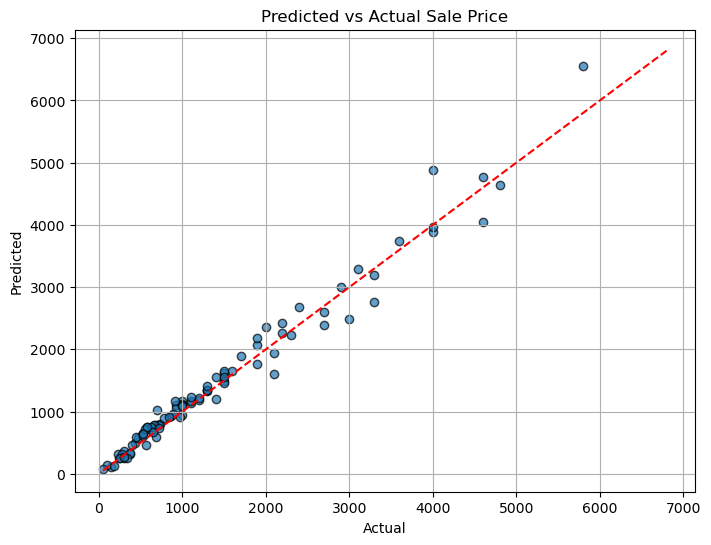

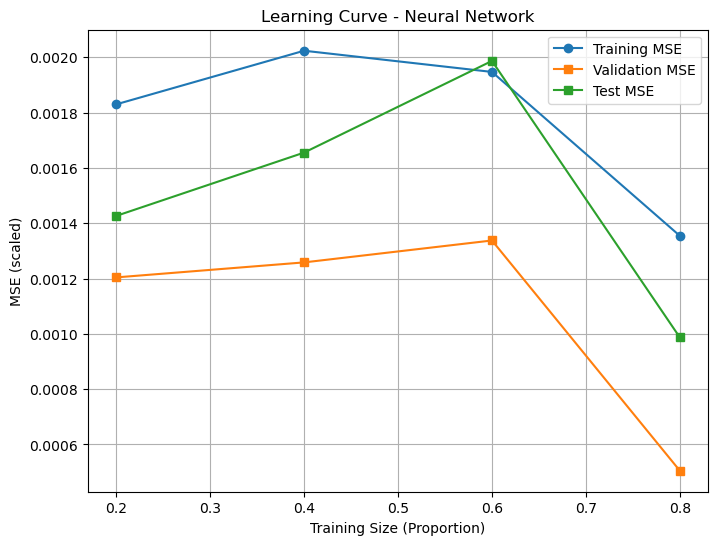

In [202]:
# Predicted vs actual scatter plot
plt.figure(figsize=(8, 6)) # we do this to visualize the relationship between actual sale prices and those predicted by the network
plt.scatter(y_test, y_pred_NN, edgecolor='k', alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--') # red line = perfect prediction
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Predicted vs Actual Sale Price")
plt.grid(True)
plt.show()

# Learning curve
train_sizes = [0.2, 0.4, 0.6, 0.8]
train_errors = []
val_errors = []
test_errors = []

for size in train_sizes:
    X_sub, X_val, y_sub, y_val = train_test_split(X_train_select, y_train_scaled, train_size=size, random_state=rd_state)
    model_NN.fit(X_sub, y_sub.ravel())
    y_sub_pred = model_NN.predict(X_sub)
    y_val_pred = model_NN.predict(X_val)
    y_test_pred = model_NN.predict(X_test_select)
    train_errors.append(mean_squared_error(y_sub, y_sub_pred))
    val_errors.append(mean_squared_error(y_val, y_val_pred))
    test_errors.append(mean_squared_error(y_test_scaled, y_test_pred))

plt.figure(figsize=(8, 6)) # to see if there is underfitting or overfitting
plt.plot(train_sizes, train_errors, marker='o', label="Training MSE")
plt.plot(train_sizes, val_errors, marker='s', label="Validation MSE")
plt.plot(train_sizes, test_errors, marker='s', label="Test MSE")
plt.xlabel("Training Size (Proportion)")
plt.ylabel("MSE (scaled)")
plt.title("Learning Curve - Neural Network")
plt.legend()
plt.grid(True)
plt.show()

The neural network predicts better than the previous models on average (except for ElasticNet), using only the "X_train_select" variables, which makes it a good predictor. However, the explanation is more complicated than for the linear models because we don't have access to the coefficients linked to the features.

# Conclusion

Finally, looking at the results, our best variable selection method is the f-regression test and our best model is the ElasticNet.